# Projeto Integrador · 3º Período · Inteligência Artificial
## Sistema Inteligente de Encaminhamento Social — avaliação do classificador

**Integrantes:** Paula Tomazzelli, Guilherme Henrique Carvalhal, Felippe Almeida, João Victor Domingues
**Instituição:** UniEVANGÉLICA · Semestre 2026/2 · **ODS** 16 (meta 16.6) e 10 (meta 10.2)

Este notebook **reproduz** a avaliação feita por `backend/app/services/ml/train_evaluator.py` (mesmas funções, mesma semente) e explica cada decisão. Ele não grava nada sobre o modelo em produção: o treino roda numa pasta temporária.

> **Limitação principal:** treino e teste ainda são **simulados**. Os números abaixo servem para validar o método; precisam ser refeitos com relatos reais do CRAS parceiro.

In [1]:
import os, sys, json, tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Importa o mesmo código usado pela API
RAIZ = os.path.abspath('..')
sys.path.insert(0, os.path.join(RAIZ, 'backend'))
from app.services.ml import train_evaluator as te
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_val_score

sns.set_theme(style='whitegrid')
pd.set_option('display.max_colwidth', 120)

### 1. Base A (real, MDS) — por que Anápolis
Resumo calculado pelo grupo a partir da base municipal do MDS (CadÚnico), já tratada conforme a seção 5 do plano (UF derivada do código IBGE, meses futuros removidos, BPC=0 a partir de ago/2026 tratado como ausente).

In [2]:
with open(os.path.join(RAIZ, 'data', 'estatisticas_anapolis_mds.json'), encoding='utf-8') as f:
    stats = json.load(f)
pd.Series(stats, name='Anápolis-GO').to_frame()

,Anápolis-GO
municipio,Anápolis
uf,GO
codigo_ibge,5201108
familias_cadunico_total,65518
familias_sem_atualizacao,8600
familias_bolsa_familia,19300
cobertura_cadunico_pct,74.5
taxa_atualizacao_cadastral_pct,86.8
ano_mes_referencia,202609


### 2. Base B (relatos rotulados) — o problema das duplicatas
O arquivo de treino tem **240 linhas**, mas muitas são a mesma frase-modelo repetida com números diferentes ("há 3 meses", "há 7 meses"). Se essas variações caem ao mesmo tempo no treino e no teste da validação cruzada, o modelo é testado em frases que já viu — e o resultado fica artificialmente perfeito.

Linhas no arquivo de treino: 240
Textos únicos:               84
Frases-modelo (grupos):      80
Relatos de teste informais:  80 (escritos à parte, linguagem de WhatsApp)


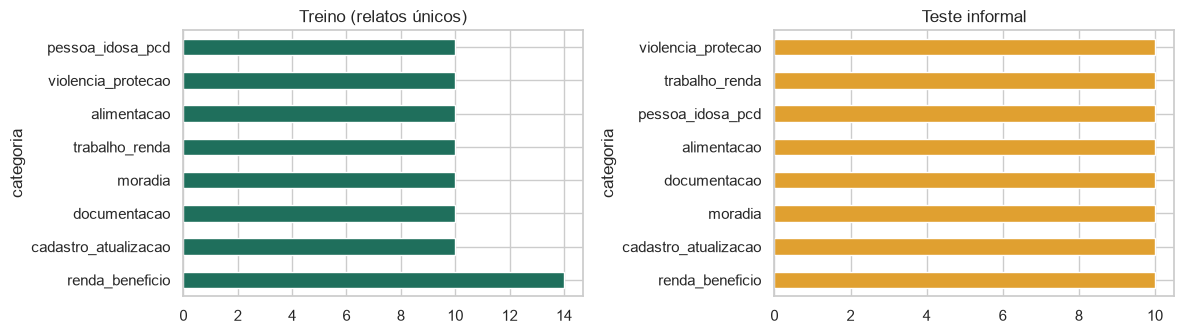

In [3]:
bruto = pd.read_json(os.path.join(RAIZ, 'data', 'relatos_treino_social.json'))
treino = te.carregar_treino()
teste = te.carregar_teste()

print(f'Linhas no arquivo de treino: {len(bruto)}')
print(f'Textos únicos:               {bruto["texto"].nunique()}')
print(f'Frases-modelo (grupos):      {treino["grupo"].nunique()}')
print(f'Relatos de teste informais:  {len(teste)} (escritos à parte, linguagem de WhatsApp)')

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
treino['categoria'].value_counts().plot.barh(ax=ax[0], color='#1f6f5c', title='Treino (relatos únicos)')
teste['categoria'].value_counts().plot.barh(ax=ax[1], color='#e0a030', title='Teste informal')
plt.tight_layout()

#### 2.1 Demonstração do vazamento
Mesmo modelo (TF-IDF + SVM linear), três formas de validar:

In [4]:
X_bruto, y_bruto = bruto['texto'].values, bruto['categoria'].values
X, y, grupos = treino['texto'].values, treino['categoria'].values, treino['grupo'].values
svm = te.modelos_candidatos()['Linear SVM'][0]

comparacao = pd.DataFrame({
    'Validação': [
        'k=5 nas 240 linhas (versão antiga)',
        'k=5 nos textos únicos, sem agrupar',
        'k=5 agrupando a frase-modelo (adotada)',
    ],
    'F1 macro': [
        cross_val_score(svm, X_bruto, y_bruto, cv=StratifiedKFold(5, shuffle=True, random_state=te.SEED), scoring='f1_macro').mean(),
        cross_val_score(svm, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=te.SEED), scoring='f1_macro').mean(),
        cross_val_score(svm, X, y, groups=grupos, cv=StratifiedGroupKFold(5, shuffle=True, random_state=te.SEED), scoring='f1_macro').mean(),
    ],
})
comparacao.round(3)

,Validação,F1 macro
0,k=5 nas 240 linhas (versão antiga),1.000
1,"k=5 nos textos únicos, sem agrupar",0.425
2,k=5 agrupando a frase-modelo (adotada),0.337


O F1 = 1,0 relatado antes vinha do vazamento. A partir daqui usamos **StratifiedGroupKFold (k=5)**, que mantém todas as variações de uma frase-modelo na mesma dobra, e um **conjunto de teste separado** que nunca é usado para treinar nem para escolher o modelo.

### 3. Treino e avaliação completa
Chamamos a mesma função da API (`train_and_evaluate`), salvando o modelo e o relatório numa pasta temporária. Ela faz:
1. linhas de base (classe majoritária e palavras-chave);
2. GridSearch de hiperparâmetros com validação cruzada agrupada para Regressão Logística, Naive Bayes e SVM linear;
3. escolha do modelo **pela validação cruzada** (nunca pelo teste);
4. limiares de confiança e de violência escolhidos com probabilidades fora da dobra;
5. avaliação no teste com IC 95% por bootstrap e teste de McNemar.

In [5]:
tmp = tempfile.mkdtemp()
rel = te.train_and_evaluate(
    output_model_path=os.path.join(tmp, 'modelo.joblib'),
    report_output_path=os.path.join(tmp, 'relatorio.json'),
)

TREINO E AVALIAÇÃO DO CLASSIFICADOR DE NECESSIDADES SOCIAIS
Treino: 84 relatos únicos em 80 frases-modelo | Teste: 80 relatos informais


Regressão Logística        CV F1=0.570±0.120 | teste F1=0.717 IC95=0.614-0.801 recall_viol=0.60


Multinomial Naive Bayes    CV F1=0.473±0.129 | teste F1=0.697 IC95=0.585-0.783 recall_viol=0.30


Linear SVM                 CV F1=0.581±0.125 | teste F1=0.692 IC95=0.582-0.774 recall_viol=0.60


Limiares escolhidos na validação cruzada: confiança=0.5 violência=0.7


----------------------------------------------------------------------
Modelo escolhido: Linear SVM (McNemar vs Regressão Logística: p=0.625)
Sistema completo no teste: F1=0.678 IC95=0.552-0.763 | recall violência=0.70 | não identificado=24%
Erros no teste: 31 de 80


### 4. Comparação com as linhas de base
Métrica principal: **F1 macro** (as classes não têm o mesmo peso no mundo real e a acurácia engana). Piso obrigatório: **revocação da classe violência/proteção** — deixar passar um caso de violência custa muito mais que um alarme falso.

In [6]:
linhas = []
for nome, b in rel['baselines'].items():
    linhas.append({'Abordagem': f'Linha de base: {nome}', 'F1 macro (CV)': b['validacao_cruzada']['f1_macro'],
                   'F1 macro (teste)': b['teste_informal']['f1_macro'], 'IC 95% (teste)': '—',
                   'Recall violência (teste)': b['teste_informal']['recall_violencia']})
for nome, r in rel['modelos_avaliados_cv5'].items():
    ic = r['teste_informal']['f1_macro_ic95']
    linhas.append({'Abordagem': nome, 'F1 macro (CV)': f"{r['f1_macro_mean']:.3f} ± {r['f1_macro_std']:.3f}",
                   'F1 macro (teste)': r['teste_informal']['f1_macro'], 'IC 95% (teste)': f'{ic[0]:.3f}–{ic[1]:.3f}',
                   'Recall violência (teste)': r['teste_informal']['recall_violencia']})
s = rel['modelo_final']['teste_sistema_completo']
linhas.append({'Abordagem': f"Sistema completo (regra de violência + {rel['modelo_final']['nome']} + palavras-chave)",
               'F1 macro (CV)': '—', 'F1 macro (teste)': s['f1_macro'],
               'IC 95% (teste)': f"{s['f1_macro_ic95'][0]:.3f}–{s['f1_macro_ic95'][1]:.3f}",
               'Recall violência (teste)': s['recall_violencia']})
tabela = pd.DataFrame(linhas)
tabela.style.format({'F1 macro (teste)': '{:.3f}', 'F1 macro (CV)': lambda v: v if isinstance(v, str) else f'{v:.3f}',
                     'Recall violência (teste)': '{:.0%}'})

,Abordagem,F1 macro (CV),F1 macro (teste),IC 95% (teste),Recall violência (teste)
0,Linha de base: classe_majoritaria,0.036,0.028,—,0%
1,Linha de base: regras_palavras_chave,0.873,0.613,—,0%
2,Regressão Logística,0.570 ± 0.120,0.717,0.614–0.801,60%
3,Multinomial Naive Bayes,0.473 ± 0.129,0.697,0.585–0.783,30%
4,Linear SVM,0.581 ± 0.125,0.692,0.582–0.774,60%
5,Sistema completo (regra de violência + Linear SVM + palavras-chave),—,0.678,0.552–0.763,70%


In [7]:
print('Hiperparâmetros escolhidos pelo GridSearch:')
for nome, r in rel['modelos_avaliados_cv5'].items():
    print(f'  {nome}: {r["melhores_hiperparametros"]}')
m = rel['comparacao_mcnemar']
print(f"\nMcNemar ({m['modelo_a']} vs {m['modelo_b']}): p = {m['p_valor']:.3f}",
      '→ diferença NÃO significativa' if m['p_valor'] >= 0.05 else '→ diferença significativa')
print(f"Limiares: confiança = {rel['modelo_final']['limiar_confianca']} | violência = {rel['modelo_final']['limiar_violencia']}")
print(f"Relatos encaminhados como 'não identificado' (Disque Social 121): {s['taxa_nao_identificado']:.0%}")

Hiperparâmetros escolhidos pelo GridSearch:
  Regressão Logística: {'clf__C': 20.0, 'tfidf__analyzer': 'char_wb', 'tfidf__ngram_range': [3, 5]}
  Multinomial Naive Bayes: {'clf__alpha': 0.1, 'tfidf__analyzer': 'char_wb', 'tfidf__ngram_range': [3, 5]}
  Linear SVM: {'clf__C': 10.0, 'tfidf__analyzer': 'char_wb', 'tfidf__ngram_range': [3, 5]}

McNemar (Linear SVM vs Regressão Logística): p = 0.625 → diferença NÃO significativa
Limiares: confiança = 0.5 | violência = 0.7
Relatos encaminhados como 'não identificado' (Disque Social 121): 24%


### 5. Matriz de confusão do sistema completo (teste)

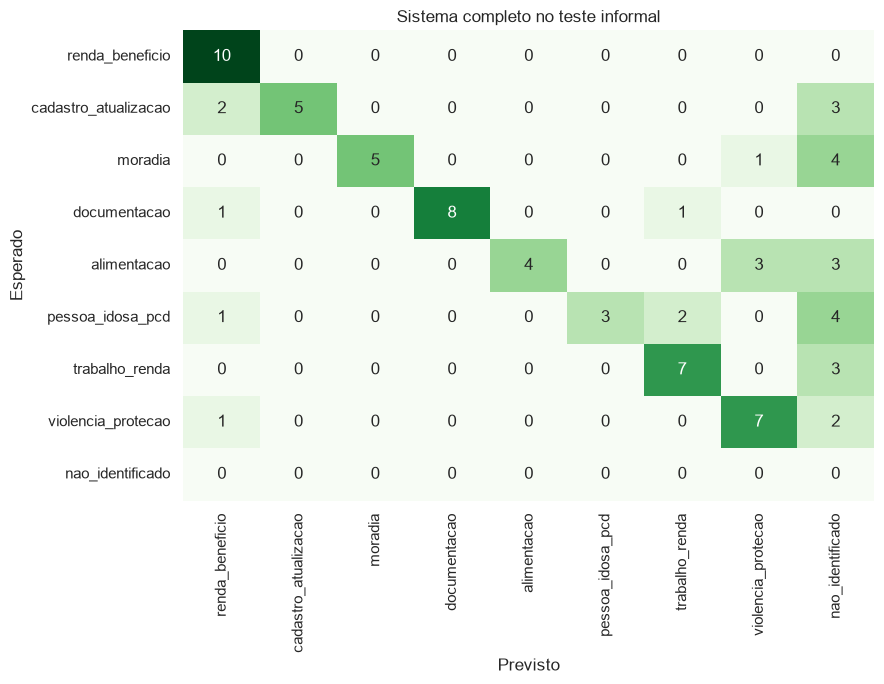

In [8]:
mf = rel['modelo_final']
cm = pd.DataFrame(mf['confusion_matrix'], index=mf['confusion_matrix_labels'], columns=mf['confusion_matrix_labels'])
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False)
plt.title('Sistema completo no teste informal')
plt.xlabel('Previsto'); plt.ylabel('Esperado')
plt.tight_layout()

### 6. Análise de erros
Quais relatos o sistema erra e qual a consequência. Erros em que um caso de **violência** vira outra categoria são os mais graves.

In [9]:
erros = pd.DataFrame(mf['erros_no_teste'])
erros['grave'] = erros['esperado'].eq(te.VIOLENCIA)
print(f'{len(erros)} erros em {rel["test_size"]} relatos; {erros["grave"].sum()} deles são violência não detectada.')
erros.sort_values('grave', ascending=False)

31 erros em 80 relatos; 3 deles são violência não detectada.


,texto,esperado,previsto,grave
30,fui estuprada e nao tive coragem de contar pra ninguem,violencia_protecao,nao_identificado,True
29,"meu ex nao para de me perseguir, aparece no meu servico e fica me vigiando",violencia_protecao,nao_identificado,True
28,meu filho bate na minha mae idosa pra pegar o dinheiro da aposentadoria dela,violencia_protecao,renda_beneficio,True
16,"meu vizinho idoso ta sem comer faz dias, ninguem leva nada pra ele",alimentacao,violencia_protecao,False
27,faco artesanato e queria vender numa feira da prefeitura,trabalho_renda,nao_identificado,False
26,queria aprender um oficio pra conseguir trabalhar,trabalho_renda,nao_identificado,False
25,"to procurando servico de qualquer coisa, sei fazer limpeza e cozinhar",trabalho_renda,nao_identificado,False
24,como consigo uma vaga em casa de repouso publica pra minha avo,pessoa_idosa_pcd,trabalho_renda,False
23,tem grupo de convivencia pra terceira idade aqui perto?,pessoa_idosa_pcd,nao_identificado,False
22,perdi a perna num acidente e nao consigo mais trabalhar,pessoa_idosa_pcd,nao_identificado,False


### 7. Explicabilidade — palavras que mais pesam
Com a Regressão Logística dá para mostrar à banca **por que** o modelo decide: os termos com maior peso positivo em cada categoria (TF-IDF por palavra, para ficar legível).

In [10]:
lr = te.modelos_candidatos()['Regressão Logística'][0].set_params(tfidf__analyzer='word', tfidf__ngram_range=(1, 2))
lr.fit(X, y)
termos = lr.named_steps['tfidf'].get_feature_names_out()
pesos = lr.named_steps['clf'].coef_
pd.DataFrame({c: [termos[i] for i in np.argsort(pesos[k])[::-1][:6]] for k, c in enumerate(lr.classes_)})

,alimentacao,cadastro_atualizacao,documentacao,moradia,pessoa_idosa_pcd,renda_beneficio,trabalho_renda,violencia_protecao
0,alimentos,unico,certidao,aluguel,deficiencia,beneficio,cursos,violencia
1,de alimentos,cadastro unico,documentos,de aluguel,centro,renda,emprego,estao
2,cesta,do,certidao de,risco,idoso,social,de emprego,medida
3,alimentar,cadunico,perdi,abrigo,anos,dinheiro,profissional,medida protetiva
4,basica,cadastro,meus documentos,pela,orientacao,dinheiro para,procuro,protetiva
5,cesta basica,meu,identidade,minha casa,tenho deficiencia,ha,receber,com meus


### 8. Conclusões para a banca
- Os modelos superam com folga a classe majoritária e superam as palavras-chave no teste informal.
- A diferença entre Regressão Logística, Naive Bayes e SVM **não é estatisticamente significativa** (McNemar) — com tão poucos dados, não dá para declarar um vencedor claro.
- A **revocação de violência ainda está abaixo de um piso aceitável**. Não "corrigimos" isso acrescentando termos tirados do próprio teste, porque isso inflaria a métrica.
- Causa principal: 84 relatos simulados não cobrem a variedade da fala real.

**Próximos passos (Ciclo 2):** relatos anonimizados do CRAS parceiro com guia de rotulagem; definir o piso de revocação de violência com um profissional; refazer esta avaliação com um conjunto de teste novo, real.